# Exercise 2:

2.1-

In [2]:
# numpy.random.randn
# importing numpy
import numpy as np

# setting the parameters
num_samples = 100
D = 10

# generating random directions
directions = np.random.randn(num_samples, D)

# testing if the rows correspond to unit vectors
print(f"Norm of the first vector: {np.linalg.norm(directions[0])}")

Norm of the first vector: 3.6642969139669033


2.1.1-
The element of "directions" follow a normal distribution.

2.1.2-
Based on the norm of first vector, the vectors generated are not unit vectors.

2.2-

In [3]:
product = directions * directions

directions * directions result to the product of each element of each vector to each self.

In [4]:
print(np.sum(product))
print(np.sum(product,axis=0))
psum = np.sum(product,axis=1)
print(psum)

999.7997521098389
[105.56943483 117.8924389   84.78831713  98.57832862 100.66948191
 110.38075664  88.53764205  94.82284185  81.26820034 117.29230982]
[13.42707187 21.03503337  7.21183544 12.34202897 11.74424279  8.30005754
 11.78795304  9.59436289  5.69592388 14.08815799 13.27160951  7.07729931
  5.50626412  9.11007612  7.76608111  8.38668807 12.21312193  7.33756857
  9.52492352 17.07486996 16.25249694  2.10806389 11.07104301  3.44198611
  6.74203263 12.76459445 10.16315346 17.85450049  3.14054164 16.02302335
  3.69600152  5.81364505 18.00047058  8.92185699 14.76612925  5.45572517
  9.34172218  9.71783728 16.20696618  8.57332742  6.26477856  6.90087871
 17.34924041 13.7289879  10.78671784  2.84275715  2.5771908   7.65640916
  9.48019199  3.7319707   4.01002913  5.36144252  9.11484543 14.31209293
  7.42822609  7.43068769  2.12848721 14.80514539 12.48015983  6.46562925
  8.75902363  7.63195482  8.00579024 11.13093884 13.08805955 11.79301547
  9.81449028  9.92679396  3.42325616 16.186960

1- sums all the data points

2- sums along the columns

3- sums along the rows and it's the one we needs to normalize the rows.

2.3-

In [5]:
# USING norms.shape=(num samples,1) or norms=norms[:,newaxis]
norms = np.sqrt(psum)[:,np.newaxis]
directions = directions/norms

In [6]:
# Checking if the rows correspond to unit vectors
print(f"Norms vectors after normalization: {np.linalg.norm(directions, axis=1)}")

Norms vectors after normalization: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1.]


# Exercise 3

In [7]:
# random search function
def random_search(g,alpha_choice,max_its,w,num_samples):
    # run random search
    weight_history = []         # container for w history
    cost_history = []           # container for corresponding cost function history
    alpha = 0
    for k in range(1,max_its+1):
        # check if diminishing steplength rule used
        if alpha_choice == 'diminishing':
            alpha = 1/float(k)
        else:
            alpha = alpha_choice
            
        # record weights and cost evaluation
        weight_history.append(w)
        cost_history.append(g(w))
        
        # construct set of random unit directions
        directions = np.random.randn(num_samples,np.size(w))
        norms = np.sqrt(np.sum(directions*directions,axis = 1))[:,np.newaxis]
        directions = directions/norms   
        
        ### pick best descent direction
        # compute all new candidate points
        w_candidates = w + alpha*directions
        
        # evaluate all candidates
        evals = np.array([g(w_val) for w_val in w_candidates])

        # if we find a real descent direction take the step in its direction
        ind = np.argmin(evals)
        if g(w_candidates[ind]) < g(w):
            # pluck out best descent direction
            d = directions[ind,:]
        
            # take step
            w = w + alpha*d
        
    # record weights and cost evaluation
    weight_history.append(w)
    cost_history.append(g(w))
    return weight_history,cost_history

In [8]:
g = lambda w: np.dot(w.T,w) + 2
alpha_choice = 1; w = np.array([3,4]); num_samples = 1000; max_its = 5
weight_history, cost_history = random_search(g,alpha_choice,max_its,w,num_samples)

3.1-

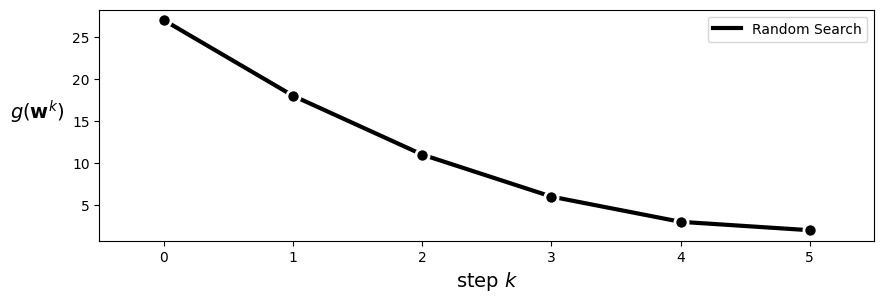

In [9]:
from MLRPlotting import static_plotter

# import custom plotting tools
static_plotter = static_plotter.Visualizer()

# plot the cost function history
static_plotter.plot_cost_histories([cost_history],start=0,points=True,labels=[r'Random Search'])

3.2-

In [ ]:
alpha_choice = 0.3; w = np.array([3,4]); num_samples = 1000; max_its = 5
weight_history, cost_history = random_search(g,alpha_choice,max_its,w,num_samples)

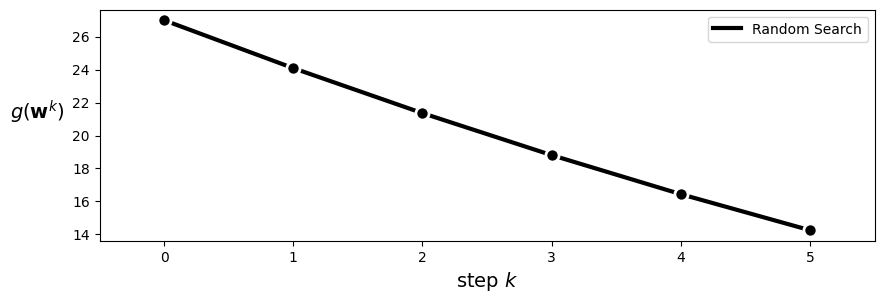

In [11]:
from MLRPlotting import static_plotter

# import custom plotting tools
static_plotter = static_plotter.Visualizer()

# plot the cost function history
static_plotter.plot_cost_histories([cost_history],start=0,points=True,labels=[r'Random Search'])

The result is worser than the previous one. The minim found is around 14 while the one in the first exemple was less than 5.

3.3-

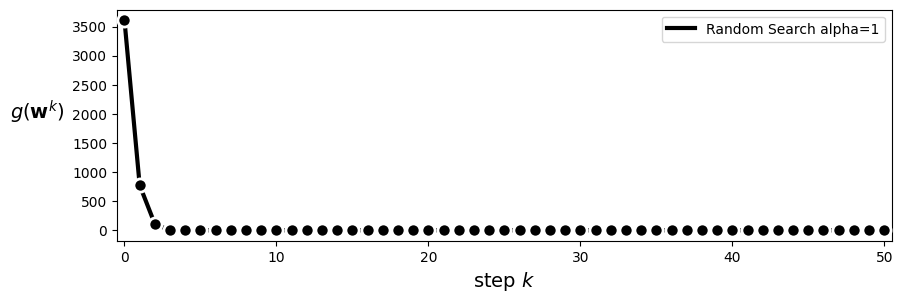

In [54]:
# defining g
def g(w): 
    return 100 * (w[1] - w[0]**2)**2 + (w[0] - 1)**2

# first run with alpha = 1
alpha_choice = 1; w = np.array([-2,-2]); num_samples = 1000; max_its = 50
weight_history_1, cost_history_1 = random_search(g,alpha_choice,max_its,w,num_samples)

# plot the cost function history
static_plotter.plot_cost_histories([cost_history_1],start=0,points=True,labels=[r'Random Search alpha=1'])

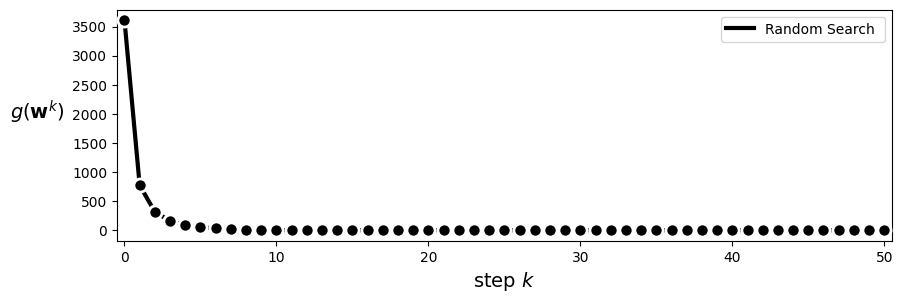

In [55]:
# first run with alpha = 1/k
alpha_choice = "diminishing"
weight_history_2, cost_history_2 = random_search(g,alpha_choice,max_its,w,num_samples)

# plot the cost function history
static_plotter.plot_cost_histories([cost_history_2],start=0,points=True,labels=[r'Random Search '])

The first plot drop a little bit faster at the beginning and both plots has the same allure afterward.

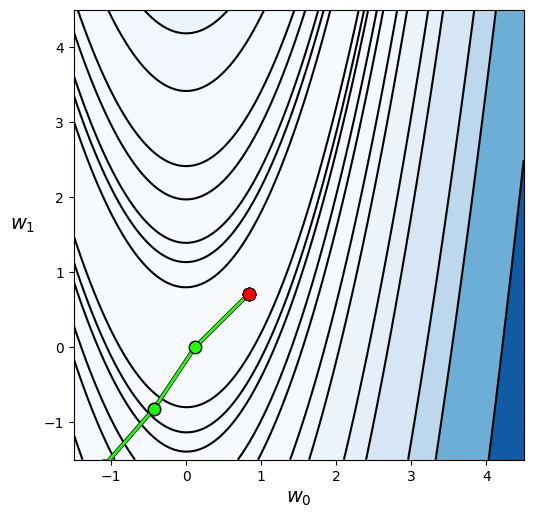

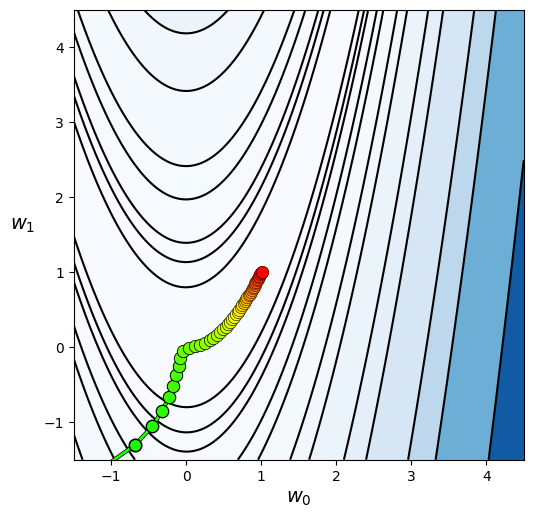

In [56]:
# contour plot of the function g with overlayed w_history
static_plotter.two_input_contour_plot(g,weight_history_1,xmin = -1.5,xmax = 4.5,ymin = -1.5,ymax = 4.5,num_contours = 30,show_original = False)
static_plotter.two_input_contour_plot(g,weight_history_2,xmin = -1.5,xmax = 4.5,ymin = -1.5,ymax = 4.5,num_contours = 30,show_original = False)

3.4-

In [57]:
# six-hump camel function
def g(w):
	term1 = (4 - 2.1 * w[0]**2 + (w[0]**4)/3) * w[0]**2
	term2 = w[0] * w[1]
	term3 = (-4 + 4 * w[1]**2) * w[1]**2
	return term1 + term2 + term3

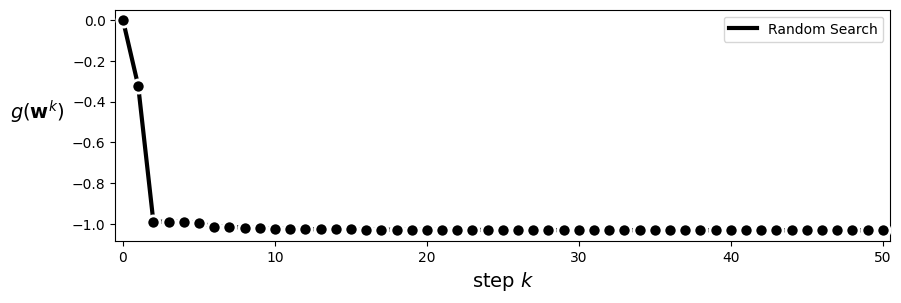

In [58]:
# first run with alpha = 1
alpha_choice = "diminishing"; w = np.array([0, 0]); num_samples = 1000; max_its = 50
weight_history, cost_history = random_search(g,alpha_choice,max_its,w,num_samples)

# plot the cost function history
static_plotter.plot_cost_histories([cost_history],start=0,points=True,labels=[r'Random Search'])

In [59]:
last_weights = weight_history[-1]
last_weights

array([ 0.08011068, -0.71158208])

We are not far from a global minimum starting from (0, 0).

# Exercise 4

In [109]:
# defining g
g = lambda w: np.dot(w.T,w) + 2

# function to generate random unit directions
def generate_random_directions(num_samples, D):
	# generating random directions
	directions = np.random.randn(num_samples, D)

	# normalizing to unit vectors
	directions = directions / np.linalg.norm(directions, axis=1)[:, np.newaxis]

	return directions

# function returning the number of decreasing directions
def Number_of_decreasing_directions(g, w0, directions):
	decreasing_dirs = 0
	for i in range(directions.shape[0]):
		if g(w0 + 0.01 * directions[i, :]) < g(w0):
			decreasing_dirs += 1
	return decreasing_dirs

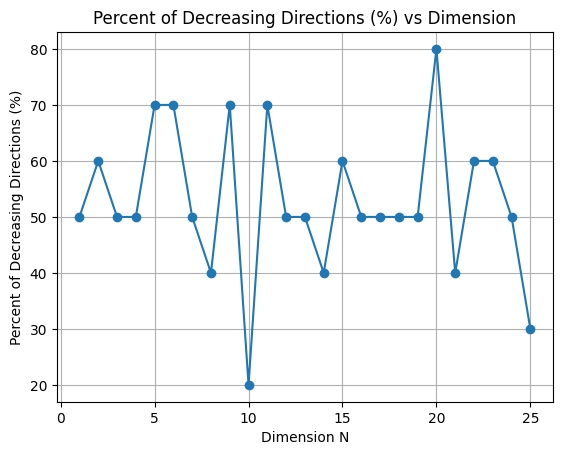

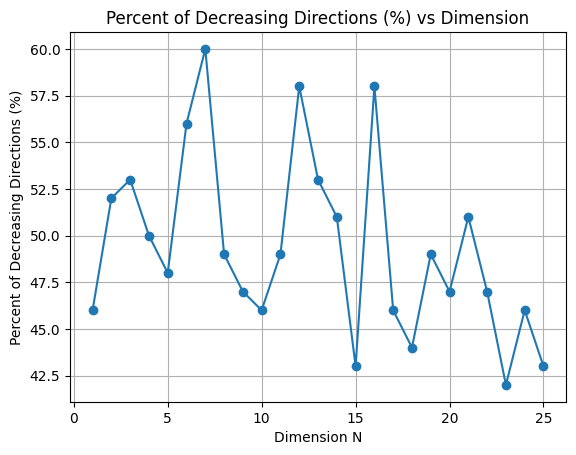

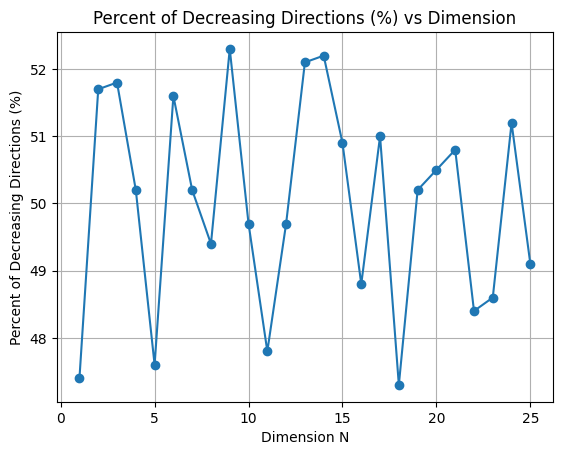

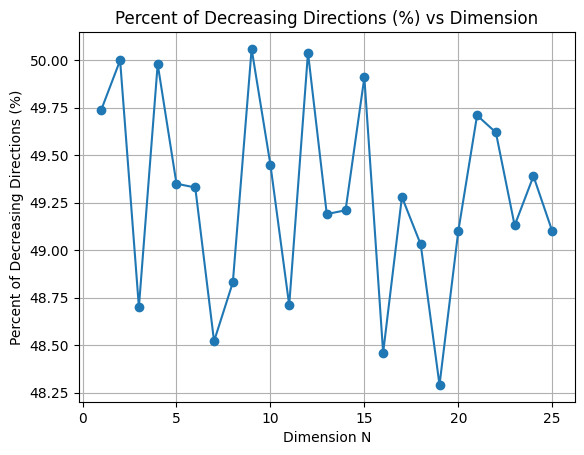

In [110]:
# function to compute and plot the number of decreasing directions vs dimension N
def decreasing_directions_vs_dimension(g, P):
	# computer the number of decreasing directions for different dimensions N
	decreasing_dirs = []
	for n in range(1, 26):
		# generate 100 random unit directions in R^n
		directions = generate_random_directions(P, n)
		
		# initialize w0
		w0 = np.zeros(n)
		w0[0] = 1
		
		# compute number of decreasing directions
		decreasing_dirs.append(Number_of_decreasing_directions(g, w0, directions) * 100 / P)
	
	# plot the results
	import matplotlib.pyplot as plt
	plt.plot(range(1, 26), decreasing_dirs, marker='o')
	plt.xlabel('Dimension N')
	plt.ylabel('Percent of Decreasing Directions (%)')
	plt.title('Percent of Decreasing Directions (%) vs Dimension')
	plt.grid()
	plt.show()

# call the function for different values of P
for P in [10, 100, 1000, 10000]:
	decreasing_directions_vs_dimension(g, P)

We observe that, first of all the majority of decreasing directions are below 60% and secondly the more we increase the dimension, the less likely we get decreasing directions. Nevertheless we have some fluctuations. 

# Exercise 5

In [92]:
# zero order coordinate search
def coordinate_search(g,alpha_choice,max_its,w):
    # construct set of all coordinate directions
    directions_plus = np.eye(np.size(w),np.size(w))
    directions_minus = - np.eye(np.size(w),np.size(w))
    directions = np.concatenate((directions_plus,directions_minus),axis=0)
        
    # run coordinate search
    weight_history = []         # container for weight history
    cost_history = []           # container for corresponding cost function history
    alpha = 0
    for k in range(1,max_its+1):        
        # check if diminishing steplength rule used
        if alpha_choice == 'diminishing':
            alpha = 1/float(k)
        else:
            alpha = alpha_choice
            
        # record weights and cost evaluation
        weight_history.append(w)
        cost_history.append(g(w))
        
        ### pick best descent direction
        # compute all new candidate points
        w_candidates = w + alpha*directions
        
        # evaluate all candidates
        evals = np.array([g(w_val) for w_val in w_candidates])

        # if we find a real descent direction take the step in its direction
        ind = np.argmin(evals)
        if g(w_candidates[ind]) < g(w):
            # pluck out best descent direction
            d = directions[ind,:]
        
            # take step
            w = w + alpha*d
        
    # record weights and cost evaluation
    weight_history.append(w)
    cost_history.append(g(w))
    return weight_history,cost_history

# zero order coordinate descent
def coordinate_descent_zero_order(g,alpha_choice,max_its,w):  
    # run coordinate search
    N = np.size(w)
    weight_history = []         # container for weight history
    cost_history = []           # container for corresponding cost function history
    alpha = 0
    for k in range(1,max_its+1):        
        # check if diminishing steplength rule used
        if alpha_choice == 'diminishing':
            alpha = 1/float(k)
        else:
            alpha = alpha_choice
        
        # random shuffle of coordinates
        c = np.random.permutation(N)
        
        # forming the dirction matrix out of the loop
        cost = g(w)
        
        # loop over each coordinate direction
        for n in range(N):
            direction = np.zeros((N,1)).flatten()
            direction[c[n]] = 1
     
            # record weights and cost evaluation
            weight_history.append(w)
            cost_history.append(cost)

            # evaluate all candidates
            evals =  [g(w + alpha*direction)]
            evals.append(g(w - alpha*direction))
            evals = np.array(evals)

            # if we find a real descent direction take the step in its direction
            ind = np.argmin(evals)
            if evals[ind] < cost_history[-1]:
                # take step
                w = w + ((-1)**(ind))*alpha*direction
                cost = evals[ind]
        
    # record weights and cost evaluation
    weight_history.append(w)
    cost_history.append(g(w))
    return weight_history,cost_history

5.2-

In [93]:
# defining g
def g(w):
    return 100 * (w[1] - w[0]**2)**2 + (w[0] - 1)**2

# parametric settings
alpha_choice = "diminishing"; w = np.array([-2,-2]); P = 40; num_samples = 1000

# running the algorithms
weight_history_cs, cost_history_cs = coordinate_search(g,alpha_choice,P,w)
weight_history_cd, cost_history_cd = coordinate_descent_zero_order(g,alpha_choice,P,w)

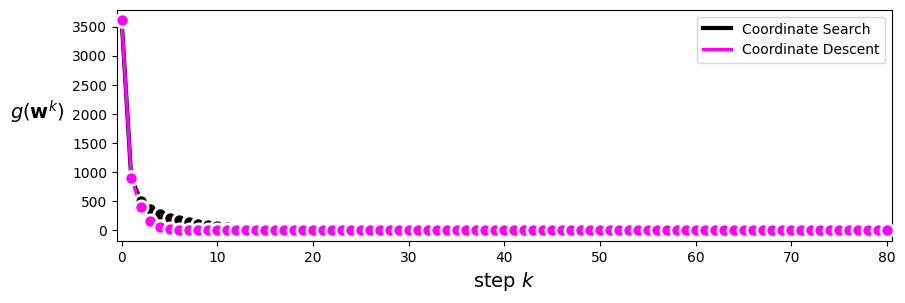

In [94]:
# plotting the cost histories
static_plotter.plot_cost_histories([cost_history_cs,cost_history_cd],start=0,points=True,labels=[r'Coordinate Search',r'Coordinate Descent'])	

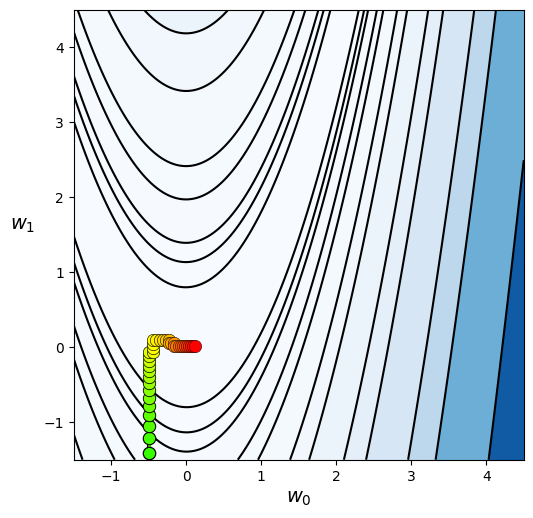

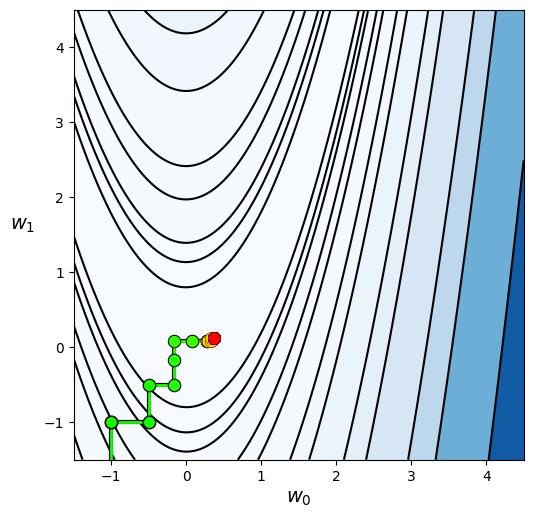

In [95]:
# contour plots of the function g with overlayed w_history
# cordinate search
static_plotter.two_input_contour_plot(g,weight_history_cs,xmin = -1.5,xmax = 4.5,ymin = -1.5,ymax = 4.5,num_contours = 30,show_original = False)
# coordinate descent
static_plotter.two_input_contour_plot(g,weight_history_cd,xmin = -1.5,xmax = 4.5,ymin = -1.5,ymax = 4.5,num_contours = 30,show_original = False)

Cordinates descent seems to be more efficient, with bigger steps at the beginning it gets futher compared to  cordinate search.